# House Prices - Notebook robusto para Kaggle

Esta version esta pensada para trabajar en Jupyter o Kaggle Notebook con el dataset House Prices - Advanced Regression Techniques.

Objetivos del flujo:

- Hacer un EDA breve, accionable y enfocado en variables que suelen mejorar el score.
- Corregir valores faltantes con reglas propias del dataset, evitando imputaciones genericas innecesarias.
- Aplicar transformaciones que ayudan al error RMSLE: log1p(SalePrice), tratamiento de asimetria y variables de calidad/superficie.
- Entrenar modelos solidos con validacion cruzada y generar una submission lista para Kaggle.

Uso esperado: coloca train.csv y test.csv en la misma carpeta de esta notebook, en la carpeta anterior, en data/, o ejecutala dentro de Kaggle.

## Que se simplifico respecto a la version original

La version original esta bien orientada para una entrega academica, pero tenia bloques que no suelen mejorar una submission de Kaggle. En esta version se quitaron o se dejaron fuera del flujo principal:

- Demostraciones de KNNImputer e IterativeImputer que no se conectaban con el modelo final.
- Regresion lineal clasica como modelo principal y pruebas de supuestos OLS, porque explican bien pero suelen dar peor RMSLE.
- Bootstrapping, enfoque bayesiano y analisis confirmatorio, utiles para interpretacion pero poco accionables para el leaderboard.
- Regresion logistica sobre precio alto/bajo, porque cambia el problema de regresion a clasificacion y no ayuda a predecir SalePrice.
- Seleccion manual reducida de variables, reemplazada por una matriz completa con ingenieria de variables y regularizacion.

El foco queda en EDA accionable, limpieza semantica, feature engineering, validacion cruzada y modelos/ensamble competitivos.

## 1. Librerias y configuracion

In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.special import boxcox1p
from scipy.stats import skew

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import RidgeCV, LassoCV, ElasticNetCV
from sklearn.kernel_ridge import KernelRidge
from sklearn.ensemble import GradientBoostingRegressor, ExtraTreesRegressor

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 140)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

RANDOM_STATE = 42
N_SPLITS = 10
N_JOBS = -1

sns.set_theme(style='whitegrid', palette='Set2')

## 2. Carga de datos

La funcion busca primero archivos locales y luego la ruta tipica de Kaggle. Asi puedes usar el mismo notebook en Jupyter local o en Kaggle sin cambiar codigo.

In [2]:
train_path = './data/train.csv'
test_path = './data/test.csv'

train = pd.read_csv(train_path)
test = pd.read_csv(test_path)

print(f'Train: {train.shape} | Test: {test.shape}')
display(train.head())

Train: (1460, 81) | Test: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0000,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0000,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,"2,003.0000",RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0000,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0000,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,"1,976.0000",RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0000,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0000,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,"2,001.0000",RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0000,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0000,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,"1,998.0000",Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0000,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0000,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,"2,000.0000",RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 3. EDA eficiente

Este EDA evita tablas decorativas que no cambian decisiones. Se enfoca en distribucion del target, faltantes importantes, variables mas asociadas al precio y outliers conocidos.

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Id,"1,460.0000",NaN,NaN,NaN,730.5000,421.6100,1.0000,365.7500,730.5000,"1,095.2500","1,460.0000"
MSSubClass,"1,460.0000",NaN,NaN,NaN,56.8973,42.3006,20.0000,20.0000,50.0000,70.0000,190.0000
MSZoning,1460,5,RL,1151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LotFrontage,"1,201.0000",NaN,NaN,NaN,70.0500,24.2848,21.0000,59.0000,69.0000,80.0000,313.0000
LotArea,"1,460.0000",NaN,NaN,NaN,"10,516.8281","9,981.2649","1,300.0000","7,553.5000","9,478.5000","11,601.5000","215,245.0000"
Street,1460,2,Pave,1454,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Alley,91,2,Grvl,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LotShape,1460,4,Reg,925,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LandContour,1460,4,Lvl,1311,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Utilities,1460,2,AllPub,1459,NaN,NaN,NaN,NaN,NaN,NaN,NaN


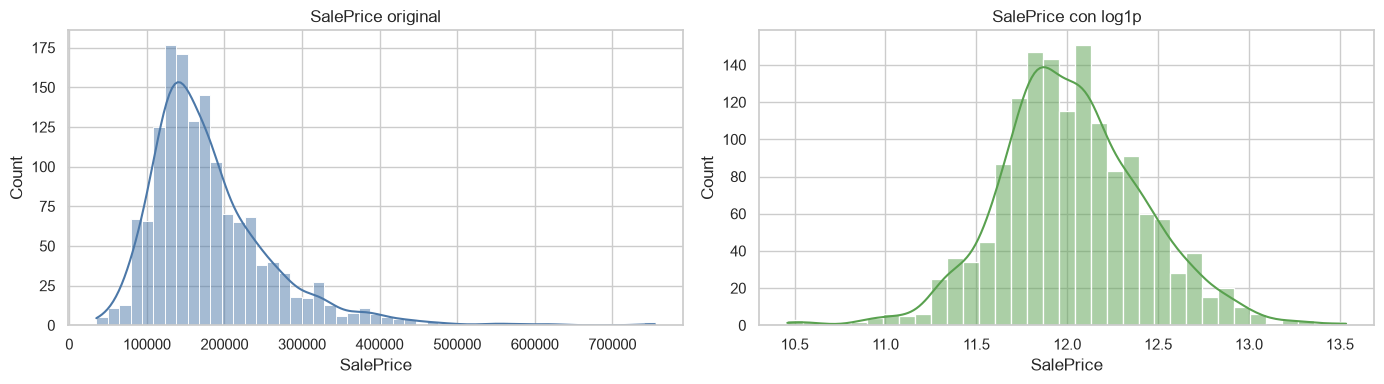

Skew SalePrice original: 1.8829
Skew log1p(SalePrice): 0.1213


In [3]:
display(train.describe(include='all').T.head(25))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(train['SalePrice'], kde=True, ax=axes[0], color='#4c78a8')
axes[0].set_title('SalePrice original')
sns.histplot(np.log1p(train['SalePrice']), kde=True, ax=axes[1], color='#59a14f')
axes[1].set_title('SalePrice con log1p')
plt.tight_layout()
plt.show()

print('Skew SalePrice original:', round(train['SalePrice'].skew(), 4))
print('Skew log1p(SalePrice):', round(np.log1p(train['SalePrice']).skew(), 4))

,missing_count,missing_pct
PoolQC,1453,0.9952
MiscFeature,1406,0.9630
Alley,1369,0.9377
Fence,1179,0.8075
MasVnrType,872,0.5973
FireplaceQu,690,0.4726
LotFrontage,259,0.1774
GarageType,81,0.0555
GarageYrBlt,81,0.0555
GarageFinish,81,0.0555


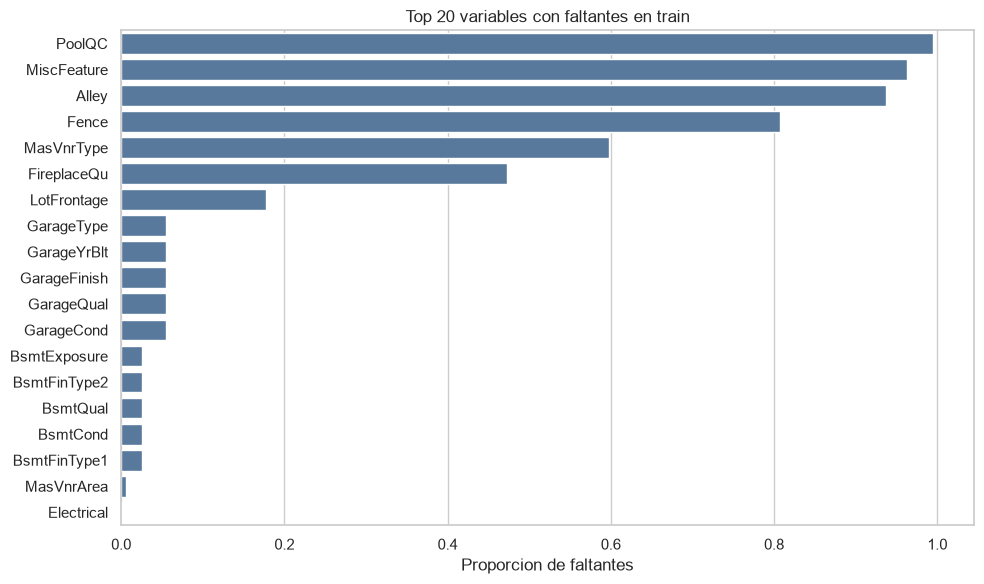

In [4]:
missing = (
    train.isna().sum()
    .loc[lambda s: s > 0]
    .sort_values(ascending=False)
    .to_frame('missing_count')
)
missing['missing_pct'] = missing['missing_count'] / len(train)
display(missing.head(25))

plt.figure(figsize=(10, 6))
sns.barplot(x='missing_pct', y=missing.head(20).index, data=missing.head(20), color='#4c78a8')
plt.title('Top 20 variables con faltantes en train')
plt.xlabel('Proporcion de faltantes')
plt.ylabel('')
plt.tight_layout()
plt.show()

,corr_with_saleprice
SalePrice,1.0000
OverallQual,0.7910
GrLivArea,0.7086
GarageCars,0.6404
GarageArea,0.6234
TotalBsmtSF,0.6136
1stFlrSF,0.6059
FullBath,0.5607
TotRmsAbvGrd,0.5337
YearBuilt,0.5229


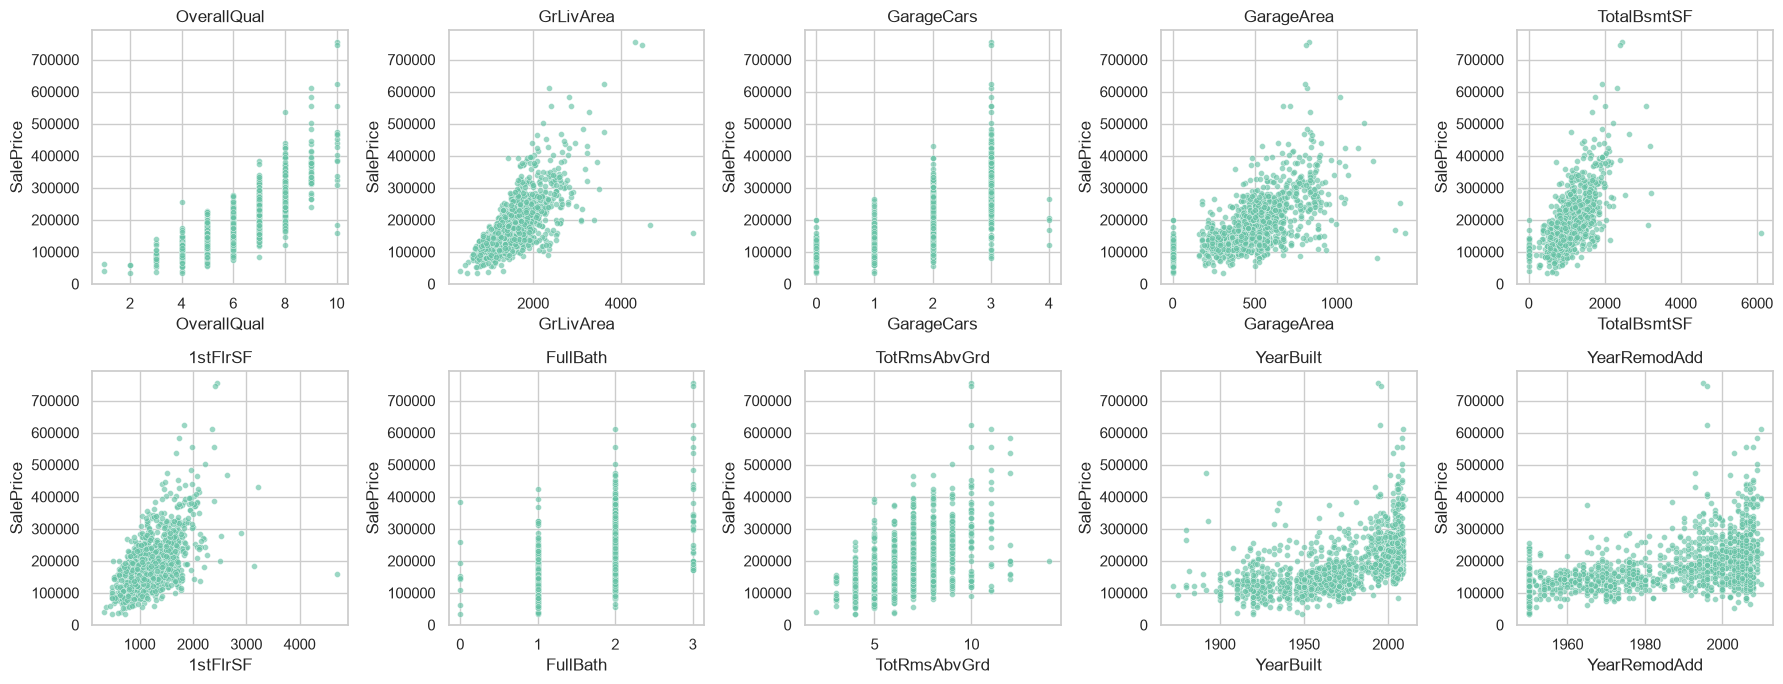

In [5]:
numeric_corr = train.select_dtypes(include=np.number).corr(numeric_only=True)['SalePrice'].sort_values(ascending=False)
display(numeric_corr.head(15).to_frame('corr_with_saleprice'))

top_corr_features = numeric_corr.drop('SalePrice').abs().sort_values(ascending=False).head(10).index.tolist()

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, col in zip(axes.ravel(), top_corr_features):
    sns.scatterplot(data=train, x=col, y='SalePrice', ax=ax, s=18, alpha=0.65)
    ax.set_title(col)
plt.tight_layout()
plt.show()

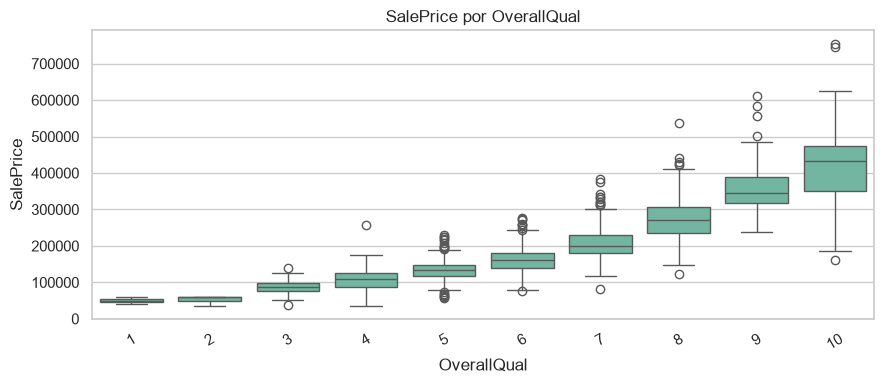

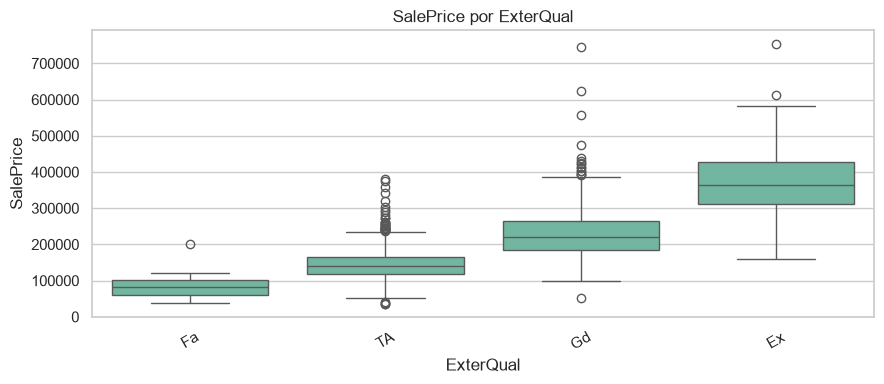

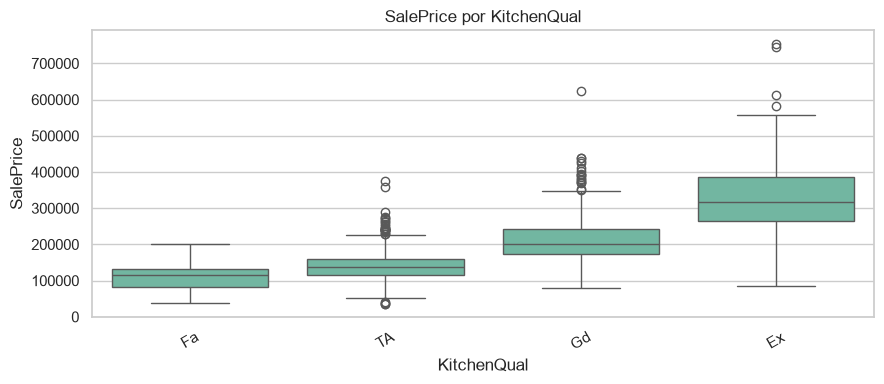

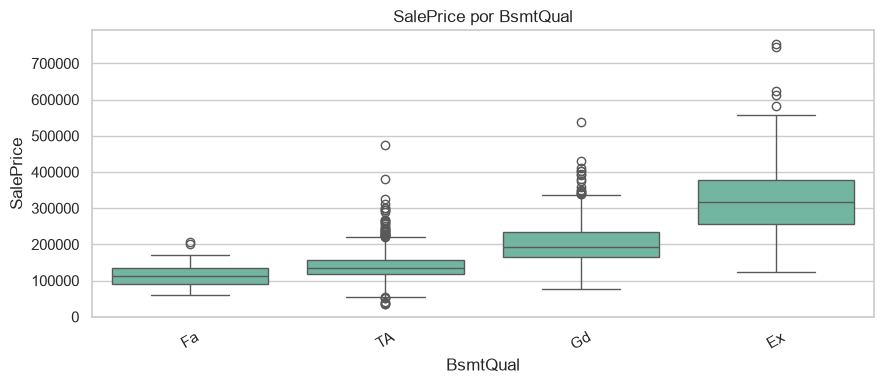

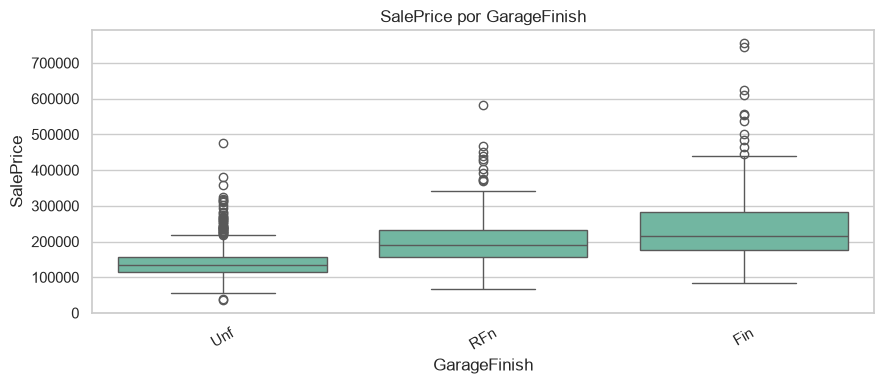

In [6]:
quality_cols = ['OverallQual', 'ExterQual', 'KitchenQual', 'BsmtQual', 'GarageFinish']
existing_quality_cols = [c for c in quality_cols if c in train.columns]

for col in existing_quality_cols:
    plt.figure(figsize=(9, 4))
    order = train.groupby(col)['SalePrice'].median().sort_values().index
    sns.boxplot(data=train, x=col, y='SalePrice', order=order)
    plt.title(f'SalePrice por {col}')
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

## 4. Outliers de alto impacto

En esta competencia suele mejorar la validacion quitar casas con area habitable extremadamente alta y precio relativamente bajo. La regla siguiente es conservadora y se aplica solo a train.

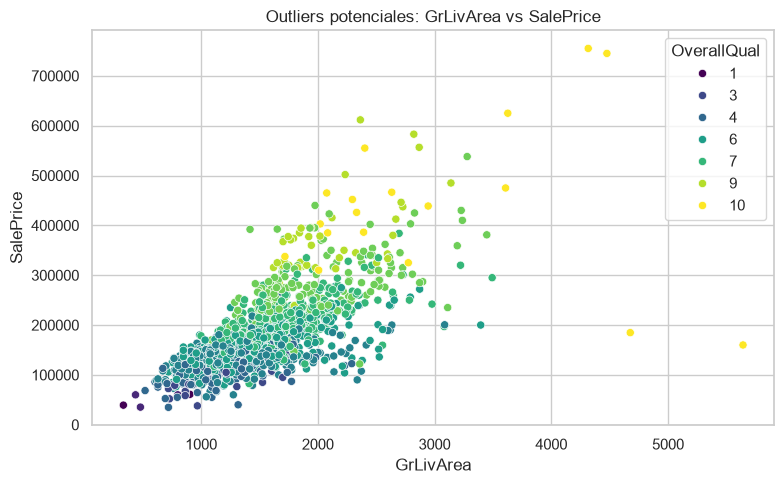

Outliers a retirar: 2
Train luego de retirar outliers: (1458, 81)


In [7]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=train, x='GrLivArea', y='SalePrice', hue='OverallQual', palette='viridis', s=35)
plt.title('Outliers potenciales: GrLivArea vs SalePrice')
plt.tight_layout()
plt.show()

outlier_mask = (train['GrLivArea'] > 4000) & (train['SalePrice'] < 300000)
print(f'Outliers a retirar: {outlier_mask.sum()}')
train = train.loc[~outlier_mask].copy()
print('Train luego de retirar outliers:', train.shape)

## 5. Limpieza e ingenieria de variables

Estrategia principal:

- Faltantes que significan ausencia real se reemplazan por None o 0.
- LotFrontage se imputa por mediana dentro de Neighborhood.
- Variables numericas que son codigos, como MSSubClass, se tratan como categoricas.
- Se crean variables de superficie total, banos totales, edad, remodelacion y banderas de presencia.
- Se transforma la asimetria de variables numericas con boxcox1p.
- Se usa one-hot encoding despues de crear todas las variables.

In [8]:
train_id = train['Id']
test_id = test['Id']

y = np.log1p(train['SalePrice'])
train_features = train.drop(['Id', 'SalePrice'], axis=1)
test_features = test.drop(['Id'], axis=1)

all_data = pd.concat([train_features, test_features], axis=0, ignore_index=True)
n_train = train_features.shape[0]

print('Datos combinados:', all_data.shape)

Datos combinados: (2917, 79)


In [9]:
none_cols = [
    'PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
    'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
    'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
    'MasVnrType'
]
for col in none_cols:
    if col in all_data.columns:
        all_data[col] = all_data[col].fillna('None')

zero_cols = [
    'GarageYrBlt', 'GarageArea', 'GarageCars',
    'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
    'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea'
]
for col in zero_cols:
    if col in all_data.columns:
        all_data[col] = all_data[col].fillna(0)

if 'LotFrontage' in all_data.columns and 'Neighborhood' in all_data.columns:
    all_data['LotFrontage'] = all_data.groupby('Neighborhood')['LotFrontage'].transform(
        lambda s: s.fillna(s.median())
    )

mode_cols = ['MSZoning', 'Electrical', 'KitchenQual', 'Exterior1st', 'Exterior2nd', 'SaleType', 'Functional']
for col in mode_cols:
    if col in all_data.columns:
        all_data[col] = all_data[col].fillna(all_data[col].mode()[0])

low_signal_cols = [col for col in ['Utilities'] if col in all_data.columns]
all_data = all_data.drop(columns=low_signal_cols)

remaining_missing = all_data.isna().sum().loc[lambda s: s > 0].sort_values(ascending=False)
display(remaining_missing.to_frame('remaining_missing'))

,remaining_missing


In [10]:
for col in ['MSSubClass', 'OverallCond', 'YrSold', 'MoSold']:
    if col in all_data.columns:
        all_data[col] = all_data[col].astype(str)

quality_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
exposure_map = {'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4}
finish_map = {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6}
garage_finish_map = {'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3}
functional_map = {'Sal': 1, 'Sev': 2, 'Maj2': 3, 'Maj1': 4, 'Mod': 5, 'Min2': 6, 'Min1': 7, 'Typ': 8}
paved_map = {'N': 0, 'P': 1, 'Y': 2}

for col in ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']:
    if col in all_data.columns:
        all_data[col + '_Score'] = all_data[col].map(quality_map).fillna(0)

if 'BsmtExposure' in all_data.columns:
    all_data['BsmtExposure_Score'] = all_data['BsmtExposure'].map(exposure_map).fillna(0)

for col in ['BsmtFinType1', 'BsmtFinType2']:
    if col in all_data.columns:
        all_data[col + '_Score'] = all_data[col].map(finish_map).fillna(0)

if 'GarageFinish' in all_data.columns:
    all_data['GarageFinish_Score'] = all_data['GarageFinish'].map(garage_finish_map).fillna(0)

if 'Functional' in all_data.columns:
    all_data['Functional_Score'] = all_data['Functional'].map(functional_map).fillna(8)

if 'PavedDrive' in all_data.columns:
    all_data['PavedDrive_Score'] = all_data['PavedDrive'].map(paved_map).fillna(0)

In [11]:
def add_feature_if_possible(df, name, cols, func):
    if all(col in df.columns for col in cols):
        df[name] = func(df)

add_feature_if_possible(all_data, 'TotalSF', ['TotalBsmtSF', '1stFlrSF', '2ndFlrSF'], lambda d: d['TotalBsmtSF'] + d['1stFlrSF'] + d['2ndFlrSF'])
add_feature_if_possible(all_data, 'TotalPorchSF', ['OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch'], lambda d: d['OpenPorchSF'] + d['EnclosedPorch'] + d['3SsnPorch'] + d['ScreenPorch'])
add_feature_if_possible(all_data, 'TotalBath', ['FullBath', 'HalfBath', 'BsmtFullBath', 'BsmtHalfBath'], lambda d: d['FullBath'] + 0.5*d['HalfBath'] + d['BsmtFullBath'] + 0.5*d['BsmtHalfBath'])
add_feature_if_possible(all_data, 'HouseAge', ['YrSold', 'YearBuilt'], lambda d: d['YrSold'].astype(int) - d['YearBuilt'])
add_feature_if_possible(all_data, 'RemodAge', ['YrSold', 'YearRemodAdd'], lambda d: d['YrSold'].astype(int) - d['YearRemodAdd'])

if {'YrSold', 'GarageYrBlt'}.issubset(all_data.columns):
    garage_age = all_data['YrSold'].astype(int) - all_data['GarageYrBlt']
    all_data['GarageAge'] = np.where(all_data['GarageYrBlt'] > 0, garage_age, 0)

for col in ['PoolArea', '2ndFlrSF', 'GarageArea', 'TotalBsmtSF', 'Fireplaces', 'MasVnrArea']:
    if col in all_data.columns:
        all_data['Has_' + col] = (all_data[col] > 0).astype(int)

if {'OverallQual', 'TotalSF'}.issubset(all_data.columns):
    all_data['Qual_x_TotalSF'] = all_data['OverallQual'] * all_data['TotalSF']

if {'OverallQual', 'ExterQual_Score', 'KitchenQual_Score'}.issubset(all_data.columns):
    all_data['OverallQualityIndex'] = all_data['OverallQual'] + all_data['ExterQual_Score'] + all_data['KitchenQual_Score']

numeric_cols = all_data.select_dtypes(include=np.number).columns
all_data[numeric_cols] = all_data[numeric_cols].replace([np.inf, -np.inf], np.nan)
all_data[numeric_cols] = all_data[numeric_cols].fillna(all_data[numeric_cols].median())

display(all_data.head())

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,ExterQual_Score,ExterCond_Score,BsmtQual_Score,BsmtCond_Score,HeatingQC_Score,KitchenQual_Score,FireplaceQu_Score,GarageQual_Score,GarageCond_Score,PoolQC_Score,BsmtExposure_Score,BsmtFinType1_Score,BsmtFinType2_Score,GarageFinish_Score,Functional_Score,PavedDrive_Score,TotalSF,TotalPorchSF,TotalBath,HouseAge,RemodAge,GarageAge,Has_PoolArea,Has_2ndFlrSF,Has_GarageArea,Has_TotalBsmtSF,Has_Fireplaces,Has_MasVnrArea,Qual_x_TotalSF,OverallQualityIndex
0,60,RL,65.0000,8450,Pave,None,Reg,Lvl,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0000,Gd,TA,PConc,Gd,TA,No,GLQ,706.0000,Unf,0.0000,150.0000,856.0000,GasA,Ex,Y,SBrkr,856,854,0,1710,1.0000,0.0000,2,1,3,1,Gd,8,Typ,0,None,Attchd,"2,003.0000",RFn,2.0000,548.0000,TA,TA,Y,0,61,0,0,0,0,None,None,None,0,2,2008,WD,Normal,4,3,4,3,5,4,0,3,3,0,1,6,1,2,8,2,"2,566.0000",61,3.5000,5,5,5.0000,0,1,1,1,0,1,"17,962.0000",15
1,20,RL,80.0000,9600,Pave,None,Reg,Lvl,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,None,0.0000,TA,TA,CBlock,Gd,TA,Gd,ALQ,978.0000,Unf,0.0000,284.0000,"1,262.0000",GasA,Ex,Y,SBrkr,1262,0,0,1262,0.0000,1.0000,2,0,3,1,TA,6,Typ,1,TA,Attchd,"1,976.0000",RFn,2.0000,460.0000,TA,TA,Y,298,0,0,0,0,0,None,None,None,0,5,2007,WD,Normal,3,3,4,3,5,3,3,3,3,0,4,5,1,2,8,2,"2,524.0000",0,2.5000,31,31,31.0000,0,0,1,1,1,0,"15,144.0000",12
2,60,RL,68.0000,11250,Pave,None,IR1,Lvl,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0000,Gd,TA,PConc,Gd,TA,Mn,GLQ,486.0000,Unf,0.0000,434.0000,920.0000,GasA,Ex,Y,SBrkr,920,866,0,1786,1.0000,0.0000,2,1,3,1,Gd,6,Typ,1,TA,Attchd,"2,001.0000",RFn,2.0000,608.0000,TA,TA,Y,0,42,0,0,0,0,None,None,None,0,9,2008,WD,Normal,4,3,4,3,5,4,3,3,3,0,2,6,1,2,8,2,"2,706.0000",42,3.5000,7,6,7.0000,0,1,1,1,1,1,"18,942.0000",15
3,70,RL,60.0000,9550,Pave,None,IR1,Lvl,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,None,0.0000,TA,TA,BrkTil,TA,Gd,No,ALQ,216.0000,Unf,0.0000,540.0000,756.0000,GasA,Gd,Y,SBrkr,961,756,0,1717,1.0000,0.0000,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,"1,998.0000",Unf,3.0000,642.0000,TA,TA,Y,0,35,272,0,0,0,None,None,None,0,2,2006,WD,Abnorml,3,3,3,4,4,4,4,3,3,0,1,5,1,1,8,2,"2,473.0000",307,2.0000,91,36,8.0000,0,1,1,1,1,0,"17,311.0000",14
4,60,RL,84.0000,14260,Pave,None,IR1,Lvl,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0000,Gd,TA,PConc,Gd,TA,Av,GLQ,655.0000,Unf,0.0000,490.0000,"1,145.0000",GasA,Ex,Y,SBrkr,1145,1053,0,2198,1.0000,0.0000,2,1,4,1,Gd,9,Typ,1,TA,Attchd,"2,000.0000",RFn,3.0000,836.0000,TA,TA,Y,192,84,0,0,0,0,None,None,None,0,12,2008,WD,Normal,4,3,4,3,5,4,3,3,3,0,3,6,1,2,8,2,"3,343.0000",84,3.5000,8,8,8.0000,0,1,1,1,1,1,"26,744.0000",16


In [12]:
numeric_features = all_data.select_dtypes(include=np.number).columns
skewness = all_data[numeric_features].apply(lambda x: skew(x.dropna())).sort_values(ascending=False)
skewed_features = skewness[skewness > 0.75].index

print(f'Variables numericas asimetricas transformadas: {len(skewed_features)}')

lambda_ = 0.15
for col in skewed_features:
    min_value = all_data[col].min()
    if min_value < 0:
        all_data[col] = all_data[col] - min_value
    all_data[col] = boxcox1p(all_data[col], lambda_)

all_data = pd.get_dummies(all_data, drop_first=False)
all_data = all_data.fillna(0)

X = all_data.iloc[:n_train].copy()
X_test = all_data.iloc[n_train:].copy()

print('X:', X.shape, '| X_test:', X_test.shape)

Variables numericas asimetricas transformadas: 28
X: (1458, 367) | X_test: (1459, 367)


## 6. Validacion RMSLE y modelos

Kaggle evalua con RMSLE. Como el target se entrena con log1p(SalePrice), usamos RMSE sobre el target logaritmico en validacion cruzada.

In [13]:
kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

def rmsle_cv(model, X_data=X, y_data=y):
    scores = np.sqrt(-cross_val_score(
        model,
        X_data,
        y_data,
        scoring='neg_mean_squared_error',
        cv=kf,
        n_jobs=N_JOBS
    ))
    return scores

ridge = make_pipeline(
    RobustScaler(),
    RidgeCV(alphas=[1, 3, 5, 7, 10, 15, 20, 30, 50, 75, 100])
)

lasso = make_pipeline(
    RobustScaler(),
    LassoCV(alphas=np.logspace(-5, -2, 60), max_iter=50000, cv=5, random_state=RANDOM_STATE)
)

elastic = make_pipeline(
    RobustScaler(),
    ElasticNetCV(
        alphas=np.logspace(-5, -2, 50),
        l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 0.99, 1.0],
        max_iter=50000,
        cv=5,
        random_state=RANDOM_STATE
    )
)

krr = make_pipeline(
    RobustScaler(),
    KernelRidge(alpha=0.6, kernel='polynomial', degree=2, coef0=2.5)
)

gbr = GradientBoostingRegressor(
    n_estimators=3000,
    learning_rate=0.01,
    max_depth=4,
    max_features='sqrt',
    min_samples_leaf=15,
    min_samples_split=10,
    loss='huber',
    random_state=RANDOM_STATE
)

extra = ExtraTreesRegressor(
    n_estimators=800,
    max_features=0.45,
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

models = {
    'Ridge': ridge,
    'Lasso': lasso,
    'ElasticNet': elastic,
    'KernelRidge': krr,
    'GradientBoosting': gbr,
    'ExtraTrees': extra,
}

Ridge            RMSLE: 0.11055 (+/- 0.01505)
Lasso            RMSLE: 0.10742 (+/- 0.01559)
ElasticNet       RMSLE: 0.10755 (+/- 0.01553)
KernelRidge      RMSLE: 0.11312 (+/- 0.01291)
GradientBoosting RMSLE: 0.11237 (+/- 0.01463)
ExtraTrees       RMSLE: 0.12730 (+/- 0.00898)


,model,mean_rmsle,std
1,Lasso,0.1074,0.0156
2,ElasticNet,0.1076,0.0155
0,Ridge,0.1106,0.0151
4,GradientBoosting,0.1124,0.0146
3,KernelRidge,0.1131,0.0129
5,ExtraTrees,0.1273,0.0090


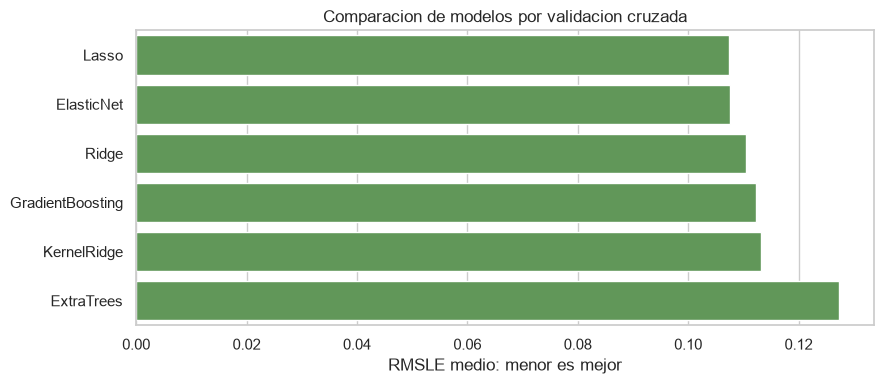

In [14]:
cv_results = []
for name, model in models.items():
    scores = rmsle_cv(model)
    cv_results.append({'model': name, 'mean_rmsle': scores.mean(), 'std': scores.std()})
    print(f'{name:16s} RMSLE: {scores.mean():.5f} (+/- {scores.std():.5f})')

cv_results = pd.DataFrame(cv_results).sort_values('mean_rmsle')
display(cv_results)

plt.figure(figsize=(9, 4))
sns.barplot(data=cv_results, x='mean_rmsle', y='model', color='#59a14f')
plt.title('Comparacion de modelos por validacion cruzada')
plt.xlabel('RMSLE medio: menor es mejor')
plt.ylabel('')
plt.tight_layout()
plt.show()

## 7. Modelo promedio robusto

El promedio ponderado suele ser estable en este dataset porque combina modelos lineales regularizados con modelos no lineales. Puedes ajustar pesos segun tu validacion local.

In [ ]:
class AveragingModel(BaseEstimator, RegressorMixin):
    def __init__(self, models, weights=None):
        self.models = models
        self.weights = weights

    def fit(self, X, y):
        self.fitted_models_ = []
        for model in self.models:
            fitted_model = clone(model)
            fitted_model.fit(X, y)
            self.fitted_models_.append(fitted_model)
        return self

    def predict(self, X):
        predictions = np.column_stack([model.predict(X) for model in self.fitted_models_])
        if self.weights is None:
            return predictions.mean(axis=1)
        return np.average(predictions, axis=1, weights=self.weights)

avg_model = AveragingModel(
    models=[ridge, lasso, elastic, krr, gbr],
    weights=[0.15, 0.25, 0.20, 0.20, 0.20]
)

avg_scores = rmsle_cv(avg_model)
print(f'AveragingModel RMSLE: {avg_scores.mean():.5f} (+/- {avg_scores.std():.5f})')

## 8. Opcional: XGBoost, LightGBM y CatBoost

Estos modelos no son obligatorios para que el notebook funcione. Si los tienes instalados, se evaluaran y puedes integrarlos al promedio final si mejoran la validacion.

In [ ]:
optional_models = {}

try:
    from xgboost import XGBRegressor
    optional_models['XGBoost'] = XGBRegressor(
        n_estimators=2500,
        learning_rate=0.015,
        max_depth=3,
        min_child_weight=2,
        subsample=0.70,
        colsample_bytree=0.70,
        reg_alpha=0.0005,
        reg_lambda=0.8,
        objective='reg:squarederror',
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
except Exception as exc:
    print('XGBoost no disponible:', exc)

try:
    from lightgbm import LGBMRegressor
    optional_models['LightGBM'] = LGBMRegressor(
        objective='regression',
        n_estimators=3000,
        learning_rate=0.01,
        num_leaves=5,
        feature_fraction=0.35,
        bagging_fraction=0.75,
        bagging_freq=5,
        min_child_samples=20,
        reg_alpha=0.005,
        reg_lambda=0.02,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=-1
    )
except Exception as exc:
    print('LightGBM no disponible:', exc)

try:
    from catboost import CatBoostRegressor
    optional_models['CatBoost'] = CatBoostRegressor(
        iterations=2500,
        learning_rate=0.02,
        depth=4,
        loss_function='RMSE',
        random_seed=RANDOM_STATE,
        verbose=False
    )
except Exception as exc:
    print('CatBoost no disponible:', exc)

optional_results = []
for name, model in optional_models.items():
    scores = rmsle_cv(model)
    optional_results.append({'model': name, 'mean_rmsle': scores.mean(), 'std': scores.std()})
    print(f'{name:16s} RMSLE: {scores.mean():.5f} (+/- {scores.std():.5f})')

if optional_results:
    display(pd.DataFrame(optional_results).sort_values('mean_rmsle'))

## 9. Entrenamiento final y submission

Se entrena con todo train y se predice test. La prediccion vuelve a escala original con expm1.

In [ ]:
final_model = clone(avg_model)
final_model.fit(X, y)

test_pred_log = final_model.predict(X_test)
test_pred = np.expm1(test_pred_log)

submission = pd.DataFrame({
    'Id': test_id,
    'SalePrice': test_pred
})

submission['SalePrice'] = submission['SalePrice'].clip(lower=0)
submission.to_csv('submission.csv', index=False)

display(submission.head())
print('Archivo creado: submission.csv')

## 10. Ideas para subir mas el score

- Probar pesos del promedio final segun los resultados de validacion cruzada.
- Instalar xgboost, lightgbm o catboost y sumarlos al promedio si mejoran RMSLE.
- Probar una regla de outliers mas amplia, pero solo si mejora CV y leaderboard publico.
- Ajustar variables por Neighborhood, por ejemplo medianas relativas de precio o interacciones Neighborhood x OverallQual.
- Mantener una separacion clara entre mejora real por CV y suerte del leaderboard publico.